# Notebook 5 — Stacking Final & Conclusion

**Objectif** : Fusionner les probabilités OOF des meilleurs modèles texte et image  
via une approche pyramidale de méta-apprentissage.

**Dépendances** : Notebooks 3 et 4 doivent avoir généré :
- `P_text_oof_train.npy` / `P_text_val.npy` / `P_text_test.npy`
- `P_image_oof_train.npy` / `P_image_val.npy` / `P_image_test.npy`

**Architecture Pyramidale** :
```
Texte OOF (27) + Image OOF (27)  →  Meta-features (81 features)  →  Meta-Classifieur  →  Prediction finale
                                     (raw probas + entropy + margin + max_conf + agreement)
```

**Livrables** :
- `models/clean/meta_best.pkl` — meilleur meta-classifieur
- `reports/figures/` — benchmark final vs SIGIR 2020
- `data/processed_clean/P_final_test.npy` — probabilités finales sur le test

---

## 0. Configuration

In [14]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

from pathlib import Path

_NB_DIR = Path('__file__').resolve().parent if '__file__' in dir() else Path.cwd()
ROOT = _NB_DIR
for _ in range(5):
    if (ROOT / 'data' / 'raw').exists():
        break
    ROOT = ROOT.parent

CFG = {
    'root':        ROOT,
    'processed':   ROOT / 'data' / 'processed_clean',
    'models_dir':  ROOT / 'models' / 'clean',
    'figures_dir': ROOT / 'reports' / 'figures',
    'split_dir':   ROOT / 'data' / 'split_no_crop2',

    'n_classes':    27,
    'random_state': 42,

    # Meta-classifieur LogReg
    'meta_logreg_C':      2.0,
    'meta_logreg_solver': 'saga',
    'meta_logreg_iter':   1000,

    # Meta-classifieur MLP
    'meta_mlp_hidden':    (256, 128, 64),
    'meta_mlp_lr':        1e-3,
    'meta_mlp_epochs':    100,
    'meta_mlp_patience':  20,
    'meta_mlp_batch':     256,

    'sigir_1st': 0.9194,  # SIGIR eCommerce Challenge 2020 — 1er place
}

for d in ['processed', 'models_dir', 'figures_dir']:
    CFG[d].mkdir(parents=True, exist_ok=True)

print(f'ROOT : {ROOT}')

ROOT : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten


## 1. Imports

In [15]:
%matplotlib inline
import pickle
import logging
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.model_selection import StratifiedKFold

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sns.set_theme(style='whitegrid')
print(f'Device : {device}')

def save_fig(name):
    plt.savefig(CFG['figures_dir'] / name, dpi=150, bbox_inches='tight')

Device : cuda


## 2. Chargement des probabilités OOF

In [16]:
y_train = np.load(CFG['processed'] / 'y_train.npy')
y_val   = np.load(CFG['processed'] / 'y_val.npy')
y_test  = np.load(CFG['processed'] / 'y_test.npy')

# DataFrames pour les features de preprocessing (langue, description, qualité image)
train_df = pd.read_csv(CFG['split_dir'] / 'train.csv')
val_df   = pd.read_csv(CFG['split_dir'] / 'val.csv')
test_df  = pd.read_csv(CFG['split_dir'] / 'test.csv')

# Probabilités Texte (notebook 3)
P_text_oof   = np.load(CFG['processed'] / 'P_text_oof_train.npy')
P_text_val   = np.load(CFG['processed'] / 'P_text_val.npy')
P_text_test  = np.load(CFG['processed'] / 'P_text_test.npy')

# Probabilités Image (notebook 4)
P_image_oof  = np.load(CFG['processed'] / 'P_image_oof_train.npy')
P_image_val  = np.load(CFG['processed'] / 'P_image_val.npy')
P_image_test = np.load(CFG['processed'] / 'P_image_test.npy')

# Baseline (notebook 2, optionnel)
baseline_path = CFG['processed'] / 'P_baseline_train.npy'
P_baseline_train = np.load(baseline_path) if baseline_path.exists() else None
P_baseline_val   = np.load(CFG['processed'] / 'P_baseline_val.npy') if baseline_path.exists() else None
P_baseline_test  = np.load(CFG['processed'] / 'P_baseline_test.npy') if baseline_path.exists() else None

print(f'P_text_oof  : {P_text_oof.shape}  P_image_oof  : {P_image_oof.shape}')
print(f'P_text_val  : {P_text_val.shape}  P_image_val  : {P_image_val.shape}')
print(f'P_text_test : {P_text_test.shape} P_image_test : {P_image_test.shape}')
print(f'DataFrames  : train={len(train_df):,}  val={len(val_df):,}  test={len(test_df):,}')

P_text_oof  : (59441, 27)  P_image_oof  : (59441, 27)
P_text_val  : (12737, 27)  P_image_val  : (12737, 27)
P_text_test : (12738, 27) P_image_test : (12738, 27)
DataFrames  : train=59,441  val=12,737  test=12,738


---
## 3. Construction des Meta-Features

### 3.1 Meta-features dérivées (méthode Veyss)

Pour chaque prédiction (texte et image), on calcule :
- **Entropie** : incertitude globale de la distribution de probabilités
- **Marge** : différence entre la 1ère et 2ème probabilité la plus élevée
- **max_conf** : probabilité maximale (confiance)
- **Accord texte/image** : 1 si les deux modèles prédisent la même classe

In [17]:
def compute_meta_features(P: np.ndarray, prefix: str = '') -> pd.DataFrame:
    """
    Calcule les meta-features a partir d une matrice de probabilites.

    Parameters
    ----------
    P      : (n_samples, n_classes)
    prefix : prefixe pour les noms de colonnes

    Returns
    -------
    DataFrame avec colonnes : entropy, margin, max_conf, pred_class
    """
    eps = 1e-12
    entropy  = -(P * np.log(P + eps)).sum(axis=1)               # entropie de Shannon
    sorted_p = np.sort(P, axis=1)[:, ::-1]
    margin   = sorted_p[:, 0] - sorted_p[:, 1]                  # marge top1 - top2
    max_conf = sorted_p[:, 0]                                    # confiance maximale
    pred_cls = P.argmax(axis=1)                                  # classe predite

    df = pd.DataFrame({
        f'{prefix}entropy':  entropy.astype(np.float32),
        f'{prefix}margin':   margin.astype(np.float32),
        f'{prefix}max_conf': max_conf.astype(np.float32),
        f'{prefix}pred':     pred_cls,
    })
    return df


def compute_agreement(P_text: np.ndarray, P_image: np.ndarray) -> np.ndarray:
    """Retourne 1 si les deux modeles predisent la meme classe, 0 sinon."""
    return (P_text.argmax(1) == P_image.argmax(1)).astype(np.float32)


def build_stacking_features(
    P_text: np.ndarray,
    P_image: np.ndarray,
    include_raw: bool = True,
) -> np.ndarray:
    """
    Assemble la matrice de meta-features pour le stacking.

    Features incluses :
    - Raw probas texte (27) + image (27) si include_raw=True
    - entropy, margin, max_conf (x2 = 6)
    - accord texte/image (1)
    Total : 27+27+6+1 = 61 features (ou 6+1 = 7 sans raw)
    """
    mf_text  = compute_meta_features(P_text,  prefix='txt_')
    mf_image = compute_meta_features(P_image, prefix='img_')
    agreement = compute_agreement(P_text, P_image).reshape(-1, 1)

    parts = []
    if include_raw:
        parts += [P_text, P_image]
    parts += [
        mf_text[['txt_entropy', 'txt_margin', 'txt_max_conf']].values,
        mf_image[['img_entropy', 'img_margin', 'img_max_conf']].values,
        agreement,
    ]
    return np.hstack(parts).astype(np.float32)


# Construction
M_train = build_stacking_features(P_text_oof,  P_image_oof)
M_val   = build_stacking_features(P_text_val,  P_image_val)
M_test  = build_stacking_features(P_text_test, P_image_test)

print(f'Meta-features : train={M_train.shape}  val={M_val.shape}  test={M_test.shape}')
print(f'  27 probas texte + 27 probas image + 6 meta (entropy/margin/max_conf) + 1 accord = {M_train.shape[1]}')

Meta-features : train=(59441, 61)  val=(12737, 61)  test=(12738, 61)
  27 probas texte + 27 probas image + 6 meta (entropy/margin/max_conf) + 1 accord = 61


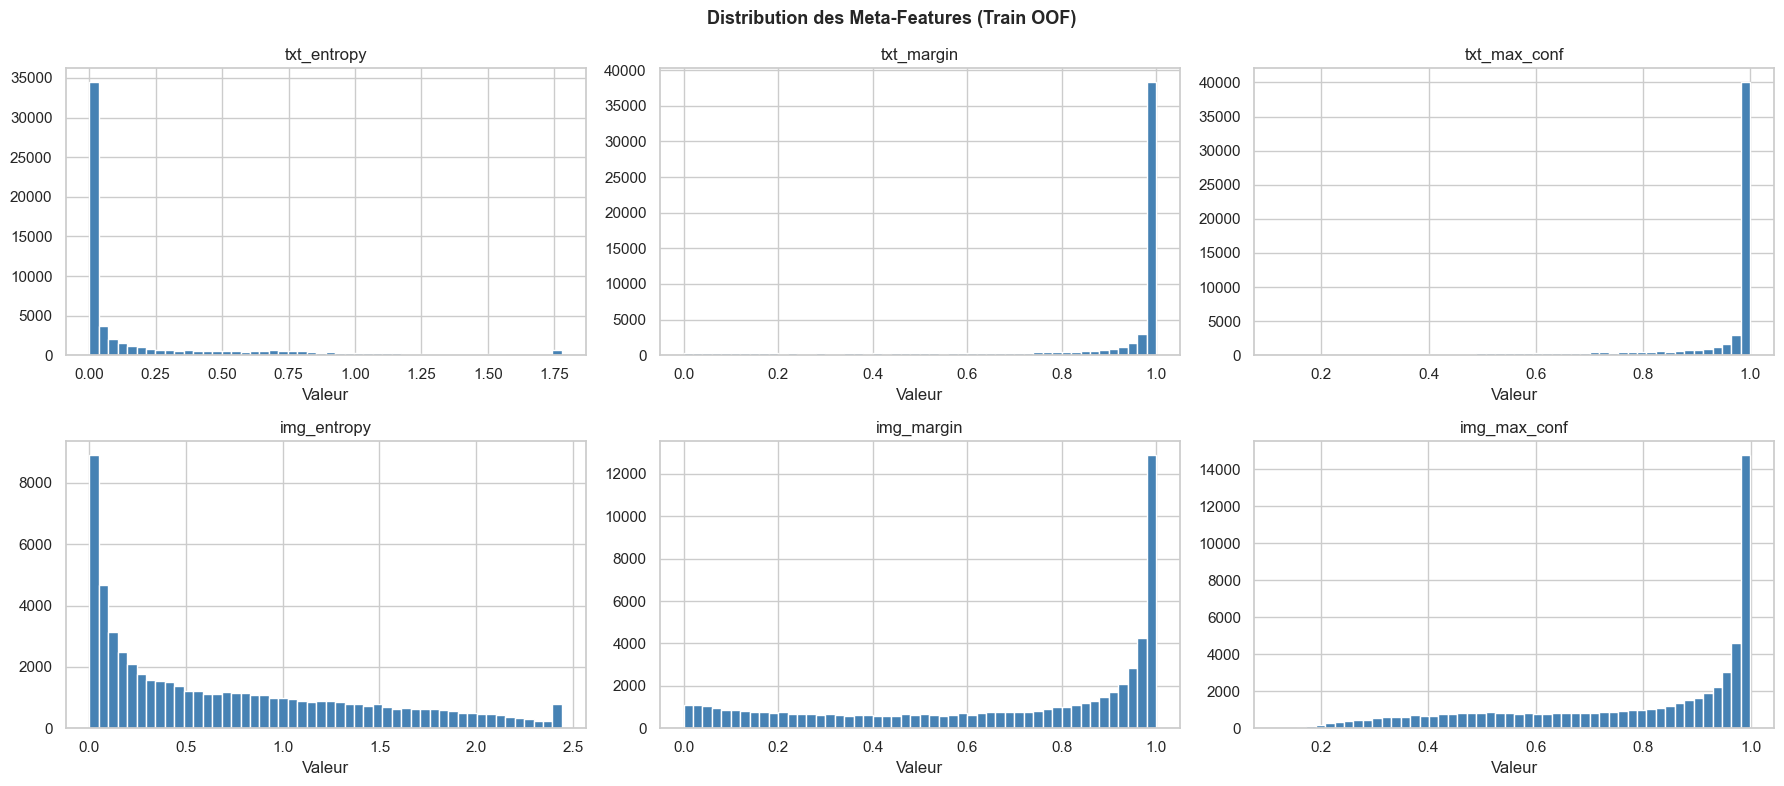

Taux d accord texte/image (train) : 73.0%


In [18]:
# Visualisation de la distribution des meta-features
mf_train_df = compute_meta_features(P_text_oof, 'txt_').join(
    compute_meta_features(P_image_oof, 'img_')
)
mf_train_df['agreement'] = compute_agreement(P_text_oof, P_image_oof)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.flatten(),
                    ['txt_entropy', 'txt_margin', 'txt_max_conf',
                     'img_entropy', 'img_margin', 'img_max_conf']):
    ax.hist(mf_train_df[col].clip(upper=mf_train_df[col].quantile(0.99)), bins=50,
            color='steelblue', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('Valeur')

plt.suptitle('Distribution des Meta-Features (Train OOF)', fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('meta_features_distribution.png')
plt.show()

print(f'Taux d accord texte/image (train) : {mf_train_df["agreement"].mean()*100:.1f}%')

In [19]:
# ── Features de preprocessing (langue, description, qualité image) ────────────
# 10 features extraites des CSV : 4 langues one-hot + 6 scalaires
PREP_FEATURE_NAMES = [
    'lang_fr', 'lang_en', 'lang_es', 'lang_de',
    'has_desc', 'len_desig', 'len_desc',
    'zoom_ratio', 'blur_score', 'is_dezoom',
]


def build_prep_features(df: pd.DataFrame) -> np.ndarray:
    """
    Extrait 10 features de preprocessing du DataFrame CSV :
    - Langue (one-hot : fr / en / es / de)
    - has_desc (binaire)
    - len_desig, len_desc (log1p — écrase les valeurs extrêmes)
    - zoom_ratio (déjà dans [0, 1])
    - blur_score (log1p — distribution très étalée à droite)
    - is_dezoom (binaire)
    """
    lang = df['language'].values
    return np.column_stack([
        (lang == 'fr').astype(np.float32),
        (lang == 'en').astype(np.float32),
        (lang == 'es').astype(np.float32),
        (lang == 'de').astype(np.float32),
        df['has_desc'].values.astype(np.float32),
        np.log1p(df['len_desig'].values).astype(np.float32),
        np.log1p(df['len_desc'].values).astype(np.float32),
        df['zoom_ratio'].fillna(0).values.astype(np.float32),
        np.log1p(df['blur_score'].fillna(0).values).astype(np.float32),
        df['is_dezoom'].values.astype(np.float32),
    ]).astype(np.float32)


F_prep_train = build_prep_features(train_df)
F_prep_val   = build_prep_features(val_df)
F_prep_test  = build_prep_features(test_df)

# 61 meta-features + 10 prep = 71 features
M_prep_train = np.hstack([M_train, F_prep_train])
M_prep_val   = np.hstack([M_val,   F_prep_val])
M_prep_test  = np.hstack([M_test,  F_prep_test])

print(f'Meta + prep : {M_prep_train.shape}  (61 stacking + 10 preprocessing)')
lang_dist = {l: (F_prep_train[:, i] == 1).sum() for i, l in enumerate(['fr','en','es','de'])}
print(f'  Langues train : {lang_dist}  |  has_desc : {int(F_prep_train[:,4].sum()):,}/{len(train_df):,}')

Meta + prep : (59441, 71)  (61 stacking + 10 preprocessing)
  Langues train : {'fr': np.int64(46166), 'en': np.int64(9055), 'es': np.int64(2207), 'de': np.int64(2013)}  |  has_desc : 38,512/59,441


### 3.2 Features Cross-Modales CLIP — Similarité Image ↔ Texte des Classes

**Principe** : CLIP est pré-entraîné pour aligner images et textes dans le même espace vectoriel.  
Pour chaque produit, on calcule la **similarité cosine** entre son embedding image CLIP (512-d, déjà normalisé)  
et les embeddings texte des 27 noms de catégories → **27 features cross-modales**.

Ces features capturent ce que CLIP a appris sur la relation visuelle-sémantique entre les produits  
et leurs catégories, information inaccessible aux features texte ou image seuls.  
Elles sont ajoutées aux meta-features existantes (61 → **88 features** pour E6).

In [20]:
# ── Matrices avec images recadrées — conditionnel sur NB4 section 6.1 ─────────
CROP_OOF_TRAIN = CFG['processed'] / 'P_I3_dino_crop_oof_train.npy'

M_crop_train = M_crop_val = M_crop_test = None
M_crop_prep_train = M_crop_prep_val = M_crop_prep_test = None

if not CROP_OOF_TRAIN.exists():
    print('[SKIP] P_I3_dino_crop_oof_train.npy absent — '
          'lancez NB4 section 6.1 pour generer les OOF sur images recadrees.')
else:
    P_I3_oof = np.load(CROP_OOF_TRAIN)
    P_I3_val = np.load(CFG['processed'] / 'P_I3_dino_crop_val.npy')
    P_I3_tst = np.load(CFG['processed'] / 'P_I3_dino_crop_test.npy')

    # Meta-features avec probas image CROP à la place des probas image originales
    M_crop_train = build_stacking_features(P_text_oof,  P_I3_oof)
    M_crop_val   = build_stacking_features(P_text_val,  P_I3_val)
    M_crop_test  = build_stacking_features(P_text_test, P_I3_tst)

    # Version enrichie : crop + preprocessing
    M_crop_prep_train = np.hstack([M_crop_train, F_prep_train])
    M_crop_prep_val   = np.hstack([M_crop_val,   F_prep_val])
    M_crop_prep_test  = np.hstack([M_crop_test,  F_prep_test])

    f1_crop_val = f1_score(y_val, P_I3_val.argmax(1), average='weighted')
    print(f'Crop OOF charges : image seule val F1={f1_crop_val:.4f}')
    print(f'M_crop_prep : {M_crop_prep_train.shape}  (61 stacking crop + 10 prep)')

Crop OOF charges : image seule val F1=0.7131
M_crop_prep : (59441, 71)  (61 stacking crop + 10 prep)


In [21]:
import open_clip
import torch.nn.functional as F_fn

CLIP_SIM_TRAIN_CACHE = CFG['processed'] / 'X_clip_sim_train.npy'
CLIP_EMB_TRAIN       = CFG['processed'] / 'X_clip_train.npy'

M_clip_train = M_clip_val = M_clip_test = None  # défaut si CLIP non disponible

if not CLIP_EMB_TRAIN.exists():
    print('[SKIP] X_clip_train.npy absent — lancez NB4 pour générer les embeddings CLIP.')
else:
    if CLIP_SIM_TRAIN_CACHE.exists():
        X_clip_sim_train = np.load(CFG['processed'] / 'X_clip_sim_train.npy').astype(np.float32)
        X_clip_sim_val   = np.load(CFG['processed'] / 'X_clip_sim_val.npy').astype(np.float32)
        X_clip_sim_test  = np.load(CFG['processed'] / 'X_clip_sim_test.npy').astype(np.float32)
        print(f'CLIP sim features chargees depuis cache : {X_clip_sim_train.shape}')
    else:
        # Embeddings images déjà normalisés (L2) — cf. NB4 section 5
        X_clip_emb_train = np.load(CFG['processed'] / 'X_clip_train.npy')
        X_clip_emb_val   = np.load(CFG['processed'] / 'X_clip_val.npy')
        X_clip_emb_test  = np.load(CFG['processed'] / 'X_clip_test.npy')

        with open(CFG['models_dir'] / 'label_encoder.pkl', 'rb') as f:
            le_tmp = pickle.load(f)

        print('Encodage CLIP text encoder — noms des 27 classes...')
        clip_sim_model, _, _ = open_clip.create_model_and_transforms(
            'ViT-B-32', pretrained='laion2b_s34b_b79k'
        )
        clip_sim_model = clip_sim_model.to(device).eval()
        tokenizer = open_clip.get_tokenizer('ViT-B-32')

        # Template qui capitalise sur la compréhension visuelle de CLIP
        class_texts = [f"a product photo of {name}" for name in le_tmp.classes_]
        tokens = tokenizer(class_texts).to(device)

        with torch.no_grad():
            text_feats = clip_sim_model.encode_text(tokens)
            text_feats = F_fn.normalize(text_feats, dim=-1).cpu().float().numpy()  # (27, 512)

        del clip_sim_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        # Similarité cosine = produit scalaire (embeddings images déjà L2-normalisés)
        X_clip_sim_train = (X_clip_emb_train @ text_feats.T).astype(np.float32)  # (n_train, 27)
        X_clip_sim_val   = (X_clip_emb_val   @ text_feats.T).astype(np.float32)
        X_clip_sim_test  = (X_clip_emb_test  @ text_feats.T).astype(np.float32)

        np.save(CFG['processed'] / 'X_clip_sim_train.npy', X_clip_sim_train)
        np.save(CFG['processed'] / 'X_clip_sim_val.npy',   X_clip_sim_val)
        np.save(CFG['processed'] / 'X_clip_sim_test.npy',  X_clip_sim_test)
        print(f'CLIP sim features sauvegardees : {X_clip_sim_train.shape}')

    # Concaténation avec les meta-features existantes : 61 + 27 = 88 features
    M_clip_train = np.hstack([M_train, X_clip_sim_train]).astype(np.float32)
    M_clip_val   = np.hstack([M_val,   X_clip_sim_val]).astype(np.float32)
    M_clip_test  = np.hstack([M_test,  X_clip_sim_test]).astype(np.float32)
    print(f'Meta-features avec CLIP sim : {M_clip_train.shape}  '
          f'(+27 similarités cross-modales)')

CLIP sim features chargees depuis cache : (59441, 27)
Meta-features avec CLIP sim : (59441, 88)  (+27 similarités cross-modales)


---
## 4. MLP Meta-Classifieur (PyTorch)

In [22]:
class MetaMLP(nn.Module):
    def __init__(self, in_dim, hidden, n_classes):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(0.3)]
            prev = h
        layers += [nn.Linear(prev, n_classes)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class MetaMLPClassifier:
    """MLP meta-classifieur PyTorch, compatible sklearn (predict_proba / score)."""

    def __init__(self, in_dim=61, hidden=(256, 128, 64), n_classes=27,
                 lr=1e-3, epochs=100, patience=20, batch=256):
        self.cfg = {
            'in_dim': in_dim, 'hidden': hidden, 'n_classes': n_classes,
            'lr': lr, 'epochs': epochs, 'patience': patience, 'batch': batch,
        }
        self.model = MetaMLP(in_dim, hidden, n_classes)

    def fit(self, X, y, X_val=None, y_val=None):
        cfg = self.cfg
        net = self.model.to(device).train()
        opt = torch.optim.Adam(net.parameters(), lr=cfg['lr'])
        criterion = nn.CrossEntropyLoss()

        Xt = torch.tensor(np.array(X), dtype=torch.float32)
        yt = torch.tensor(np.array(y), dtype=torch.long)
        dl = DataLoader(TensorDataset(Xt, yt), batch_size=cfg['batch'], shuffle=True)

        best_loss, patience_ctr, best_state = float('inf'), 0, None
        Xv = yv = None
        if X_val is not None:
            Xv = torch.tensor(np.array(X_val), dtype=torch.float32).to(device)
            yv = torch.tensor(np.array(y_val),  dtype=torch.long).to(device)

        for _ in range(cfg['epochs']):
            net.train()
            for xb, yb in dl:
                opt.zero_grad()
                criterion(net(xb.to(device)), yb.to(device)).backward()
                opt.step()

            if Xv is not None:
                net.eval()
                with torch.no_grad():
                    val_loss = criterion(net(Xv), yv).item()
                if val_loss < best_loss:
                    best_loss = val_loss
                    best_state = {k: v.clone() for k, v in net.state_dict().items()}
                    patience_ctr = 0
                else:
                    patience_ctr += 1
                    if patience_ctr >= cfg['patience']:
                        break

        if best_state is not None:
            net.load_state_dict(best_state)
        self.model = net
        return self

    def predict_proba(self, X):
        import torch.nn.functional as F
        self.model.eval()
        with torch.no_grad():
            Xt = torch.tensor(np.array(X), dtype=torch.float32).to(device)
            return F.softmax(self.model(Xt), dim=1).cpu().numpy()

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def score(self, X, y):
        from sklearn.metrics import accuracy_score
        return accuracy_score(y, self.predict(X))

print('MetaMLP + MetaMLPClassifier définis.')

MetaMLP + MetaMLPClassifier définis.


In [23]:
def run_experiment(
    name: str,
    X_tr: np.ndarray, y_tr: np.ndarray,
    X_vl: np.ndarray, y_vl: np.ndarray,
    X_te: np.ndarray, y_te: np.ndarray,
    clf,
) -> dict:
    """
    Entraine le meta-classifieur et evalue sur Val et Test.
    - MetaMLPClassifier : fit(X, y, X_val, y_val) pour early stopping
    - LGBMClassifier    : fit(X, y, eval_set=...) pour early stopping natif
    - Autres (LogReg)   : fit(X, y) standard
    """
    cache_path = CFG['models_dir'] / f'meta_{name}.pkl'

    if cache_path.exists():
        with open(cache_path, 'rb') as f:
            clf = pickle.load(f)
        print(f'[CACHE] {name}')
    else:
        if isinstance(clf, MetaMLPClassifier):
            clf.fit(X_tr, y_tr, X_vl, y_vl)
        elif isinstance(clf, lgb.LGBMClassifier):
            clf.fit(X_tr, y_tr,
                    eval_set=[(X_vl, y_vl)],
                    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False),
                               lgb.log_evaluation(period=-1)])
        else:
            clf.fit(X_tr, y_tr)
        with open(cache_path, 'wb') as f:
            pickle.dump(clf, f)

    P_vl = clf.predict_proba(X_vl)
    P_te = clf.predict_proba(X_te)
    f1_vl = f1_score(y_vl, P_vl.argmax(1), average='weighted')
    f1_te = f1_score(y_te, P_te.argmax(1), average='weighted')
    print(f'[{name}] Val={f1_vl:.4f}  Test={f1_te:.4f}')
    return {'name': name, 'F1_Val': round(f1_vl, 4), 'F1_Test': round(f1_te, 4),
            'clf': clf, 'P_val': P_vl, 'P_test': P_te}


in_dim = M_train.shape[1]
n_cl   = CFG['n_classes']

# ── E0 : référence NB2 (baseline TF-IDF LightGBM, chargée depuis probas) ─────
results = []
_bl_path = CFG['processed'] / 'P_baseline_test.npy'
_bl_val_path = CFG['processed'] / 'P_baseline_val.npy'
if _bl_path.exists():
    P_bl_te = np.load(_bl_path)
    P_bl_vl = np.load(_bl_val_path) if _bl_val_path.exists() else P_bl_te
    f1_bl_vl = f1_score(y_val,  P_bl_vl.argmax(1), average='weighted') if _bl_val_path.exists() else None
    f1_bl_te = f1_score(y_test, P_bl_te.argmax(1), average='weighted')
    results.append({
        'name': 'E0_baseline_nb2', 'ref': True,
        'F1_Val': round(f1_bl_vl, 4) if f1_bl_vl else None,
        'F1_Test': round(f1_bl_te, 4),
        'clf': None, 'P_val': P_bl_vl, 'P_test': P_bl_te,
    })
    _vl_str = f'{f1_bl_vl:.4f}' if f1_bl_vl else '—'
    print(f'[E0_baseline_nb2] Val={_vl_str}  Test={f1_bl_te:.4f}')
else:
    print('[E0_baseline_nb2] Probas NB2 non trouvees — ignoree.')

experiments = [
    # E1 — baseline unimodale texte
    ('E1_text_only',
     P_text_oof, P_text_val, P_text_test,
     LogisticRegression(C=CFG['meta_logreg_C'], solver=CFG['meta_logreg_solver'],
                        max_iter=CFG['meta_logreg_iter'], class_weight='balanced',
                        n_jobs=-1, multi_class='multinomial')),

    # E2 — baseline unimodale image
    ('E2_image_only',
     P_image_oof, P_image_val, P_image_test,
     LogisticRegression(C=CFG['meta_logreg_C'], solver=CFG['meta_logreg_solver'],
                        max_iter=CFG['meta_logreg_iter'], class_weight='balanced',
                        n_jobs=-1, multi_class='multinomial')),

    # E3 — fusion bimodale brute, classifieur linéaire
    ('E3_text_image_logreg',
     np.hstack([P_text_oof, P_image_oof]),
     np.hstack([P_text_val, P_image_val]),
     np.hstack([P_text_test, P_image_test]),
     LogisticRegression(C=CFG['meta_logreg_C'], solver=CFG['meta_logreg_solver'],
                        max_iter=CFG['meta_logreg_iter'], class_weight='balanced',
                        n_jobs=-1, multi_class='multinomial')),

    # E4 — meta-features complets (probas + 7 scalaires), classifieur linéaire
    ('E4_meta_logreg',
     M_train, M_val, M_test,
     LogisticRegression(C=CFG['meta_logreg_C'], solver=CFG['meta_logreg_solver'],
                        max_iter=CFG['meta_logreg_iter'], class_weight='balanced',
                        n_jobs=-1, multi_class='multinomial')),

    # E5 — meta-features, gradient boosting
    ('E5_meta_lgbm',
     M_train, M_val, M_test,
     lgb.LGBMClassifier(objective='multiclass', num_class=n_cl,
                        num_leaves=63, learning_rate=0.05, n_estimators=300,
                        subsample=0.8, colsample_bytree=0.8,
                        class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)),

    # E6 — meta-features, MLP non-linéaire
    ('E6_meta_mlp',
     M_train, M_val, M_test,
     MetaMLPClassifier(in_dim=in_dim, hidden=CFG['meta_mlp_hidden'], n_classes=n_cl,
                       lr=CFG['meta_mlp_lr'], epochs=CFG['meta_mlp_epochs'],
                       patience=CFG['meta_mlp_patience'], batch=CFG['meta_mlp_batch'])),

    # E7 — meta-features + features preprocessing (langue, desc, qualité image)
    ('E7_meta_prep_mlp',
     M_prep_train, M_prep_val, M_prep_test,
     MetaMLPClassifier(in_dim=M_prep_train.shape[1], hidden=CFG['meta_mlp_hidden'],
                       n_classes=n_cl, lr=CFG['meta_mlp_lr'], epochs=CFG['meta_mlp_epochs'],
                       patience=CFG['meta_mlp_patience'], batch=CFG['meta_mlp_batch'])),
]

# E8 — images recadrées + preprocessing (conditionnel)
if M_crop_prep_train is not None:
    experiments.append((
        'E8_crop_prep_mlp',
        M_crop_prep_train, M_crop_prep_val, M_crop_prep_test,
        MetaMLPClassifier(in_dim=M_crop_prep_train.shape[1], hidden=CFG['meta_mlp_hidden'],
                          n_classes=n_cl, lr=CFG['meta_mlp_lr'], epochs=CFG['meta_mlp_epochs'],
                          patience=CFG['meta_mlp_patience'], batch=CFG['meta_mlp_batch']),
    ))

for exp_name, X_tr, X_vl, X_te, clf in experiments:
    r = run_experiment(exp_name, X_tr, y_train, X_vl, y_val, X_te, y_test, clf)
    results.append(r)

bench_df = (
    pd.DataFrame([{'Experiment': r['name'], 'F1_Val': r['F1_Val'], 'F1_Test': r['F1_Test']}
                  for r in results])
    .sort_values('F1_Test', ascending=False)
    .reset_index(drop=True)
)
print('\n=== BENCHMARK STACKING ===')
print(bench_df.to_string(index=False))


[E0_baseline_nb2] Val=0.8262  Test=0.8321
[CACHE] E1_text_only
[E1_text_only] Val=0.8646  Test=0.8642
[CACHE] E2_image_only
[E2_image_only] Val=0.7534  Test=0.7462
[CACHE] E3_text_image_logreg
[E3_text_image_logreg] Val=0.8815  Test=0.8825
[CACHE] E4_meta_logreg
[E4_meta_logreg] Val=0.8828  Test=0.8823
[CACHE] E5_meta_lgbm
[E5_meta_lgbm] Val=0.8756  Test=0.8785
[CACHE] E6_meta_mlp
[E6_meta_mlp] Val=0.8845  Test=0.8845
[CACHE] E7_meta_prep_mlp
[E7_meta_prep_mlp] Val=0.8880  Test=0.8879
[CACHE] E8_crop_prep_mlp
[E8_crop_prep_mlp] Val=0.8850  Test=0.8849

=== BENCHMARK STACKING ===
          Experiment  F1_Val  F1_Test
    E7_meta_prep_mlp  0.8880   0.8879
    E8_crop_prep_mlp  0.8850   0.8849
         E6_meta_mlp  0.8845   0.8845
E3_text_image_logreg  0.8815   0.8825
      E4_meta_logreg  0.8828   0.8823
        E5_meta_lgbm  0.8756   0.8785
        E1_text_only  0.8646   0.8642
     E0_baseline_nb2  0.8262   0.8321
       E2_image_only  0.7534   0.7462


---
## 5. Benchmark des Expériences de Stacking

Progression de la moins bonne performance vers la meilleure :

| Exp | Features                                          | Classifieur      | Dimension |
|-----|---------------------------------------------------|------------------|-----------|
| E0  | Référence NB2 (TF-IDF + LightGBM)                | LightGBM (NB2)   | —         |
| E1  | Texte seul (OOF probas)                           | LogReg           | 27        |
| E2  | Image seule (OOF probas)                          | LogReg           | 27        |
| E3  | Texte + Image (OOF probas brutes)                 | LogReg           | 54        |
| E4  | Texte + Image + Meta-scalaires                    | LogReg           | 61        |
| E5  | Texte + Image + Meta-scalaires                    | LightGBM         | 61        |
| E6  | Texte + Image + Meta-scalaires                    | MLP              | 61        |
| E7  | Texte + Image + Meta + Preprocessing (10)         | MLP              | 71        |
| E8  | Texte + Image Crop + Meta + Preprocessing (10)    | MLP (conditionnel) | 71      |


---
## 5.1 Expériences avec CamemBERT

Nécessite que NB3 section 9 ait généré les fichiers `P_camembert_*.npy`.
Même logique que E7/E8 : nocrop puis crop conditionnel.

| Exp | Features | Classifieur | Images | Dim |
|-----|----------|-------------|--------|-----|
| E10_cam_nocrop | CamemBERT OOF + Image best + Meta | MetaMLP | Standard (meilleur NB4) | 61 |
| E11_cam_crop | CamemBERT OOF + DINOv2 Crop + Meta | MetaMLP | Crop (si NB4 sect. 6.1) | 61 |

In [57]:
CAM_OOF_PATH  = CFG['processed'] / 'P_camembert_oof_train.npy'
CAM_VAL_PATH  = CFG['processed'] / 'P_camembert_val.npy'
CAM_TEST_PATH = CFG['processed'] / 'P_camembert_test.npy'

if not CAM_OOF_PATH.exists():
    print('[SKIP] P_camembert_oof_train.npy absent — lancez NB3 section 9.')
else:
    P_cam_oof  = np.load(CAM_OOF_PATH)
    P_cam_val  = np.load(CAM_VAL_PATH)
    P_cam_test = np.load(CAM_TEST_PATH)

    # ── Détection du modèle image best (NB4) ──────────────────────────────────
    img_label = 'img_best'
    for candidate in ['I1_dino_mlp', 'I2_clip_mlp', 'dino_ft', 'resnet50_ft']:
        cand_path = CFG['processed'] / f'P_{candidate}_oof_train.npy'
        if cand_path.exists():
            try:
                if np.allclose(np.load(cand_path), P_image_oof, atol=1e-6):
                    img_label = candidate
                    break
            except Exception:
                pass
    print(f'Modèle image best détecté : {img_label}')

    cam_results = []

    # ── E10 : CamemBERT + meilleur modèle image (nocrop) ─────────────────────
    print(f'\n=== E10_cam_nocrop : CamemBERT + {img_label} ===')
    M_tr = build_stacking_features(P_cam_oof,  P_image_oof)
    M_vl = build_stacking_features(P_cam_val,  P_image_val)
    M_te = build_stacking_features(P_cam_test, P_image_test)

    r_e10 = run_experiment(
        f'E10_cam_{img_label}_nocrop',
        M_tr, y_train, M_vl, y_val, M_te, y_test,
        MetaMLPClassifier(
            in_dim=M_tr.shape[1], hidden=CFG['meta_mlp_hidden'],
            n_classes=CFG['n_classes'], lr=CFG['meta_mlp_lr'],
            epochs=CFG['meta_mlp_epochs'], patience=CFG['meta_mlp_patience'],
            batch=CFG['meta_mlp_batch'],
        ),
    )
    cam_results.append({'Experiment': f'E10_cam_{img_label}_nocrop',
                        'F1_Val': r_e10['F1_Val'], 'F1_Test': r_e10['F1_Test']})

    # ── E11 : CamemBERT + DINOv2 Crop (conditionnel) ─────────────────────────
    CROP_OOF = CFG['processed'] / 'P_I3_dino_crop_oof_train.npy'
    if not CROP_OOF.exists():
        print('\n[SKIP] E11_cam_crop — P_I3_dino_crop_oof_train.npy absent (lancez NB4 sect. 6.1)')
    else:
        P_crop_oof  = np.load(CROP_OOF)
        P_crop_val  = np.load(CFG['processed'] / 'P_I3_dino_crop_val.npy')
        P_crop_test = np.load(CFG['processed'] / 'P_I3_dino_crop_test.npy')

        print('\n=== E11_cam_crop : CamemBERT + DINOv2 Crop ===')
        M_tr_c = build_stacking_features(P_cam_oof,  P_crop_oof)
        M_vl_c = build_stacking_features(P_cam_val,  P_crop_val)
        M_te_c = build_stacking_features(P_cam_test, P_crop_test)

        r_e11 = run_experiment(
            'E11_cam_dino_crop',
            M_tr_c, y_train, M_vl_c, y_val, M_te_c, y_test,
            MetaMLPClassifier(
                in_dim=M_tr_c.shape[1], hidden=CFG['meta_mlp_hidden'],
                n_classes=CFG['n_classes'], lr=CFG['meta_mlp_lr'],
                epochs=CFG['meta_mlp_epochs'], patience=CFG['meta_mlp_patience'],
                batch=CFG['meta_mlp_batch'],
            ),
        )
        cam_results.append({'Experiment': 'E11_cam_dino_crop',
                            'F1_Val': r_e11['F1_Val'], 'F1_Test': r_e11['F1_Test']})

    # ── Benchmark augmenté ────────────────────────────────────────────────────
    bench_augmented = (
        pd.concat(
            [bench_df[['Experiment', 'F1_Val', 'F1_Test']], pd.DataFrame(cam_results)],
            ignore_index=True,
        )
        .sort_values('F1_Test', ascending=False)
        .reset_index(drop=True)
    )
    print('\n=== BENCHMARK AUGMENTÉ (avec CamemBERT) ===')
    print(bench_augmented.to_string(index=False))


Modèle image best détecté : I2_clip_mlp

=== E10_cam_nocrop : CamemBERT + I2_clip_mlp ===
[CACHE] E10_cam_I2_clip_mlp_nocrop
[E10_cam_I2_clip_mlp_nocrop] Val=0.8988  Test=0.8963

=== E11_cam_crop : CamemBERT + DINOv2 Crop ===
[CACHE] E11_cam_dino_crop
[E11_cam_dino_crop] Val=0.8947  Test=0.8948

=== BENCHMARK AUGMENTÉ (avec CamemBERT) ===
                Experiment  F1_Val  F1_Test
E10_cam_I2_clip_mlp_nocrop  0.8988   0.8963
         E11_cam_dino_crop  0.8947   0.8948
          E7_meta_prep_mlp  0.8880   0.8879
          E8_crop_prep_mlp  0.8850   0.8849
               E6_meta_mlp  0.8845   0.8845
      E3_text_image_logreg  0.8815   0.8825
            E4_meta_logreg  0.8828   0.8823
              E5_meta_lgbm  0.8756   0.8785
              E1_text_only  0.8646   0.8642
           E0_baseline_nb2  0.8262   0.8321
             E2_image_only  0.7534   0.7462


---
## 6. Interprétabilité — SHAP sur MetaMLP

Analyse SHAP (`DeepExplainer`) sur le meilleur MetaMLP du benchmark.
- **Bar plot** : importance globale (mean |SHAP| sur toutes les classes et tous les échantillons)
- **Beeswarm** : direction et magnitude des contributions par feature

MetaMLP sélectionné : E10_cam_I2_clip_mlp_nocrop  (in_dim=61)
Calcul SHAP (DeepExplainer)...


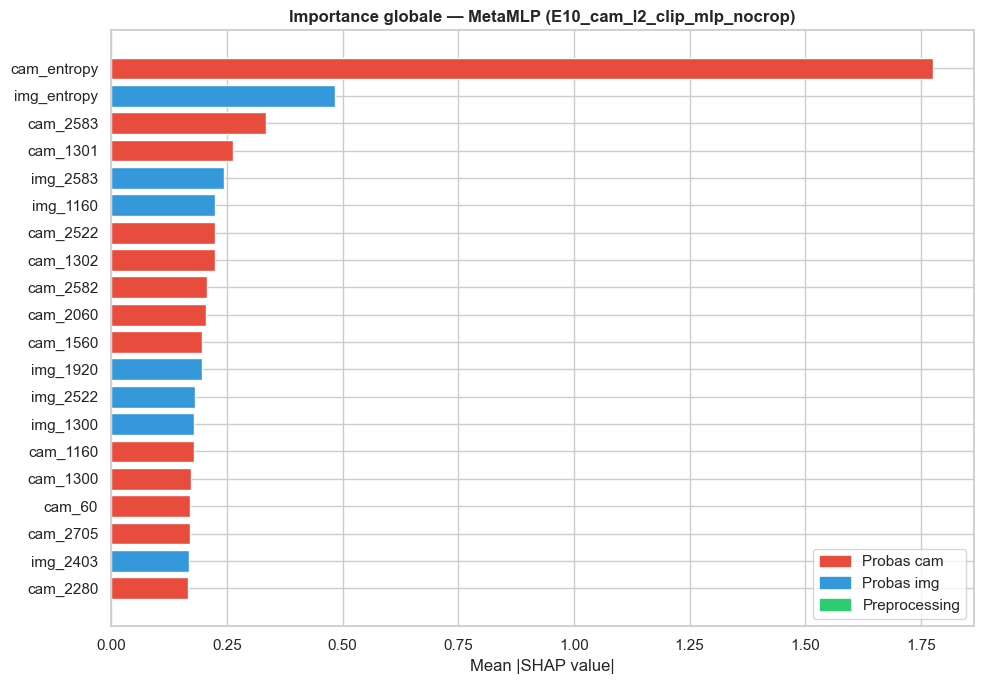

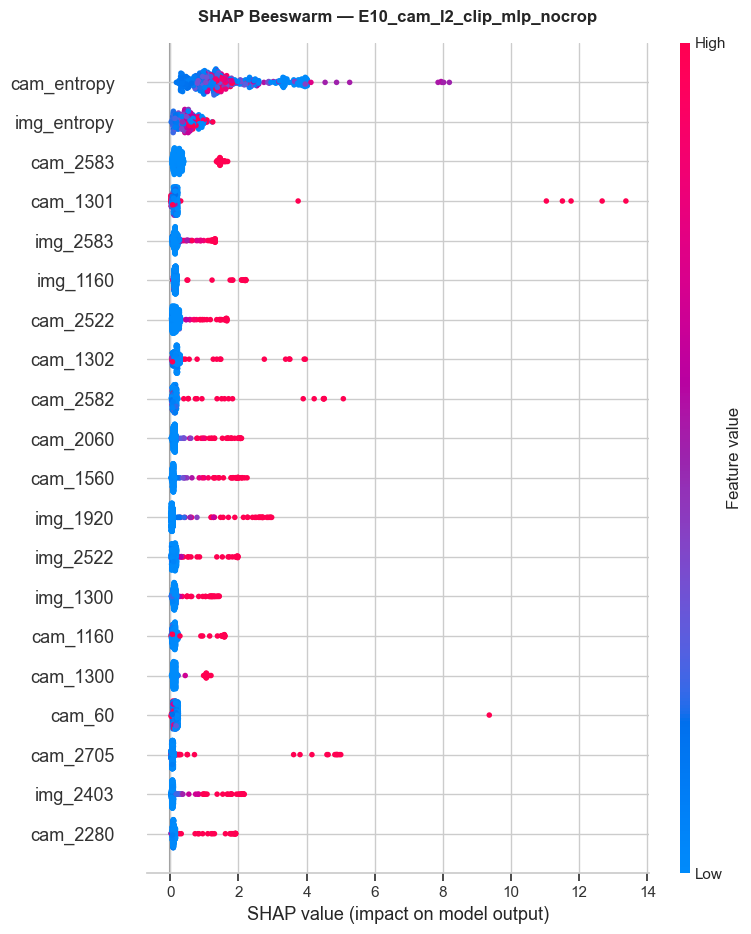

Figures sauvegardées : shap_global_importance.png, shap_beeswarm.png


In [48]:
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'shap'])
    import shap

# ── Trouver le meilleur MetaMLP ───────────────────────────────────────────────
_bench = bench_augmented if 'bench_augmented' in dir() else bench_df

best_exp, best_clf = None, None
for exp in _bench.sort_values('F1_Test', ascending=False)['Experiment']:
    cache = CFG['models_dir'] / f'meta_{exp}.pkl'
    if cache.exists():
        try:
            with open(cache, 'rb') as f:
                clf = pickle.load(f)
            if isinstance(clf, MetaMLPClassifier):
                best_exp, best_clf = exp, clf
                break
        except Exception:
            pass

if best_clf is None:
    print('[SKIP] Aucun MetaMLP mis en cache — lancez les expériences d\'abord.')
else:
    net    = best_clf.model.eval()
    in_dim = net.net[0].in_features
    print(f'MetaMLP sélectionné : {best_exp}  (in_dim={in_dim})')

    # ── Noms de classes réels (prdtypecodes) ──────────────────────────────────
    with open(CFG['models_dir'] / 'label_encoder.pkl', 'rb') as f:
        le = pickle.load(f)
    class_names = [str(c) for c in le.classes_]  # ex. ['10', '40', '50', ...]

    # ── Feature names lisibles ────────────────────────────────────────────────
    PREP_NAMES = ['lang_fr', 'lang_en', 'lang_es', 'lang_de',
                  'has_desc', 'len_desig', 'len_desc',
                  'zoom_ratio', 'blur_score', 'is_dezoom']

    is_cam  = 'cam' in best_exp
    is_crop = 'crop' in best_exp and 'nocrop' not in best_exp
    txt_lbl = 'cam'       if is_cam  else 'txt'
    img_lbl = 'dino_crop' if is_crop else 'img'

    base_feat = (
        [f'{txt_lbl}_{c}' for c in class_names] +   # ex. txt_10, txt_40 ... ou cam_10 ...
        [f'{img_lbl}_{c}' for c in class_names] +   # ex. img_10, img_40 ...
        [f'{txt_lbl}_entropy', f'{txt_lbl}_margin', f'{txt_lbl}_max_conf',
         f'{img_lbl}_entropy', f'{img_lbl}_margin', f'{img_lbl}_max_conf',
         'agreement']
    )  # 61

    # ── Sélection de la matrice de features ──────────────────────────────────
    if is_cam:
        P_t_tr = np.load(CFG['processed'] / 'P_camembert_oof_train.npy')
        P_t_vl = np.load(CFG['processed'] / 'P_camembert_val.npy')
    else:
        P_t_tr, P_t_vl = P_text_oof, P_text_val

    if is_crop:
        P_i_tr = np.load(CFG['processed'] / 'P_I3_dino_crop_oof_train.npy')
        P_i_vl = np.load(CFG['processed'] / 'P_I3_dino_crop_val.npy')
    else:
        P_i_tr, P_i_vl = P_image_oof, P_image_val

    X_tr_arr = build_stacking_features(P_t_tr, P_i_tr)
    X_vl_arr = build_stacking_features(P_t_vl, P_i_vl)
    feat_names = base_feat.copy()

    if in_dim == 71:
        X_tr_arr   = np.hstack([X_tr_arr, build_prep_features(train_df)])
        X_vl_arr   = np.hstack([X_vl_arr, build_prep_features(val_df)])
        feat_names = feat_names + PREP_NAMES

    assert X_vl_arr.shape[1] == in_dim, \
        f'Dimension mismatch : features={X_vl_arr.shape[1]} vs modèle={in_dim}'

    # ── DeepExplainer ─────────────────────────────────────────────────────────
    np.random.seed(42)
    X_bg   = torch.tensor(X_tr_arr[np.random.choice(len(X_tr_arr), 200, replace=False)],
                          dtype=torch.float32).to(device)
    X_shap = torch.tensor(X_vl_arr[np.random.choice(len(X_vl_arr), 500, replace=False)],
                          dtype=torch.float32).to(device)

    print('Calcul SHAP (DeepExplainer)...')
    explainer   = shap.DeepExplainer(net, X_bg)
    shap_values = explainer.shap_values(X_shap)

    # Normalise selon le format retourné par la version de SHAP :
    #   - liste de 27 tableaux (n_samples, n_features)  → stack → (27, n, f) → mean axis=0
    #   - tableau (n_samples, n_features, n_classes)              → mean axis=-1
    #   - tableau (n_classes, n_samples, n_features)              → mean axis=0
    sv = np.array(shap_values)
    n_samp = X_shap.shape[0]
    if sv.ndim == 3 and sv.shape[0] == n_samp:      # (n_samples, n_features, n_classes)
        mean_abs_shap = np.mean(np.abs(sv), axis=-1)
    elif sv.ndim == 3:                               # (n_classes, n_samples, n_features)
        mean_abs_shap = np.mean(np.abs(sv), axis=0)
    else:                                            # déjà (n_samples, n_features)
        mean_abs_shap = np.abs(sv)
    # mean_abs_shap : (n_samples, n_features)

    # ── Plot 1 : Importance globale (bar) ─────────────────────────────────────
    global_imp = mean_abs_shap.mean(axis=0)
    top20_idx  = np.argsort(global_imp)[::-1][:20]

    def _feat_color(name):
        if txt_lbl in name:  return '#e74c3c'
        if img_lbl in name:  return '#3498db'
        return '#2ecc71'

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(
        [feat_names[i] for i in top20_idx[::-1]],
        global_imp[top20_idx[::-1]],
        color=[_feat_color(feat_names[i]) for i in top20_idx[::-1]],
    )
    ax.set_xlabel('Mean |SHAP value|')
    ax.set_title(f'Importance globale — MetaMLP ({best_exp})', fontweight='bold')
    from matplotlib.patches import Patch
    ax.legend(handles=[
        Patch(color='#e74c3c', label=f'Probas {txt_lbl}'),
        Patch(color='#3498db', label=f'Probas {img_lbl}'),
        Patch(color='#2ecc71', label='Preprocessing'),
    ], loc='lower right')
    plt.tight_layout()
    save_fig('shap_global_importance.png')
    plt.show()

    # ── Plot 2 : Beeswarm ─────────────────────────────────────────────────────
    shap.summary_plot(
        mean_abs_shap, X_shap.cpu().numpy(),
        feature_names=feat_names, max_display=20, show=False,
    )
    plt.title(f'SHAP Beeswarm — {best_exp}', fontweight='bold', pad=15)
    plt.tight_layout()
    save_fig('shap_beeswarm.png')
    plt.show()

    print('Figures sauvegardées : shap_global_importance.png, shap_beeswarm.png')


---
## 6. Sélection & Export du meilleur modèle

In [61]:
_bench = bench_augmented if 'bench_augmented' in dir() else bench_df
best_exp = _bench.iloc[0]['Experiment']

# Chercher dans results (session courante)
best_result = next((r for r in results if r['name'] == best_exp), None)

# Fallback : charger depuis cache pkl si l'exp n'est pas en mémoire (ex. E10/E11)
if best_result is None:
    cache = CFG['models_dir'] / f'meta_{best_exp}.pkl'
    if not cache.exists():
        raise FileNotFoundError(f'Modèle introuvable : {cache}. Relancez la cellule e9e10_cd0.')
    with open(cache, 'rb') as f:
        clf = pickle.load(f)

    is_cam  = 'cam' in best_exp
    is_crop = 'crop' in best_exp and 'nocrop' not in best_exp

    P_t_te = np.load(CFG['processed'] / 'P_camembert_test.npy') if is_cam else P_text_test
    P_i_te = np.load(CFG['processed'] / 'P_I3_dino_crop_test.npy') if is_crop else P_image_test
    X_te   = build_stacking_features(P_t_te, P_i_te)

    P_te   = clf.predict_proba(X_te)
    f1_te  = f1_score(y_test, P_te.argmax(1), average='weighted')

    # Val : reconstruire aussi
    P_t_vl = np.load(CFG['processed'] / 'P_camembert_val.npy') if is_cam else P_text_val
    P_i_vl = np.load(CFG['processed'] / 'P_I3_dino_crop_val.npy') if is_crop else P_image_val
    X_vl   = build_stacking_features(P_t_vl, P_i_vl)
    P_vl   = clf.predict_proba(X_vl)
    f1_vl  = f1_score(y_val, P_vl.argmax(1), average='weighted')

    best_result = {
        'name': best_exp, 'F1_Val': round(f1_vl, 4), 'F1_Test': round(f1_te, 4),
        'clf': clf, 'P_val': P_vl, 'P_test': P_te,
    }
    print(f'[CACHE] {best_exp} rechargé depuis pkl')

P_final_test = best_result['P_test']
np.save(CFG['processed'] / 'P_final_test.npy', P_final_test)

with open(CFG['models_dir'] / 'meta_best.pkl', 'wb') as f:
    pickle.dump(best_result['clf'], f)

print(f'Meilleure experience : {best_exp}')
print(f'F1 Val  : {best_result["F1_Val"]:.4f}')
print(f'F1 Test : {best_result["F1_Test"]:.4f}')


[CACHE] E10_cam_I2_clip_mlp_nocrop rechargé depuis pkl
Meilleure experience : E10_cam_I2_clip_mlp_nocrop
F1 Val  : 0.8988
F1 Test : 0.8963


---
## 7. Benchmark Final

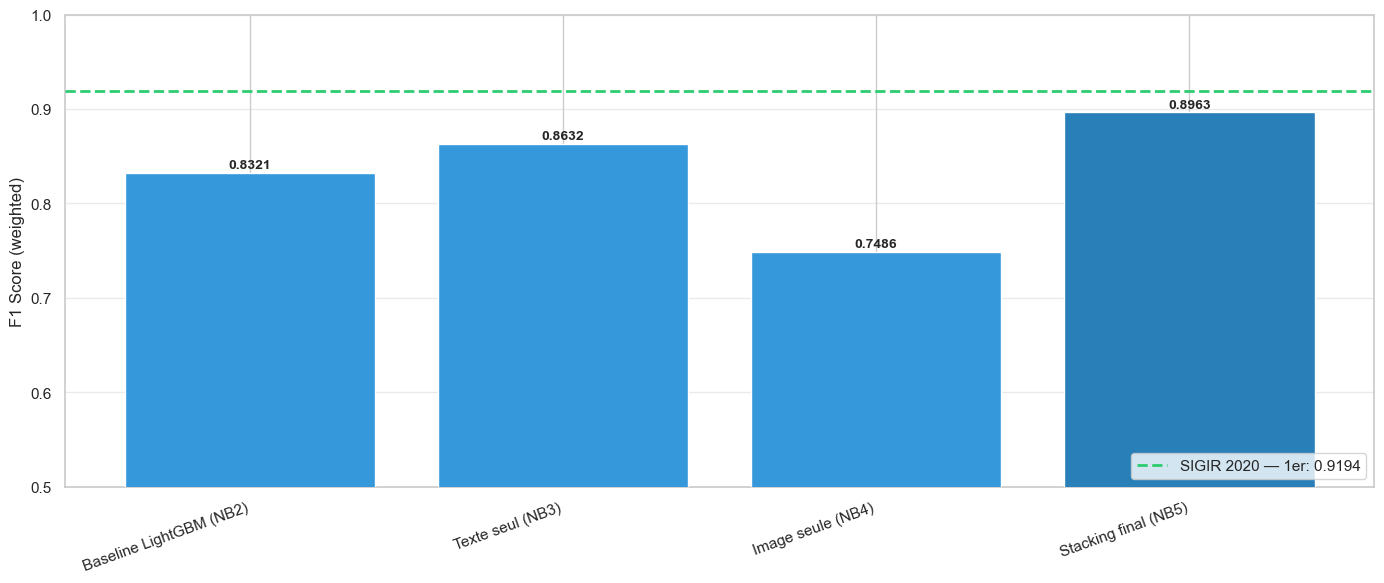


Nos resultats vs SIGIR 2020 (1er place) :
  Notre meilleur score  : 0.8963
  SIGIR 2020 1er place  : 0.9194  (ecart : -0.0231)


In [62]:
# Resultats de reference SIGIR 2020
# Source : https://sigir-ecom.github.io/ecom2020/cfp.html
sigir_refs = [
    ('SIGIR 2020 — 1er', CFG['sigir_1st'],      '#2ecc71'),
]

# Nos resultats
our_results = [
    ('Baseline LightGBM (NB2)',  None),
    ('Texte seul (NB3)',          None),
    ('Image seule (NB4)',         None),
    ('Stacking final (NB5)',      None),
]

# Chargement des scores si disponibles
baseline_test_path = CFG['processed'] / 'P_baseline_test.npy'
if baseline_test_path.exists():
    P_bl = np.load(baseline_test_path)
    our_results[0] = ('Baseline LightGBM (NB2)', f1_score(y_test, P_bl.argmax(1), average='weighted'))

P_tx = np.load(CFG['processed'] / 'P_text_test.npy')
our_results[1] = ('Texte seul (NB3)', f1_score(y_test, P_tx.argmax(1), average='weighted'))

P_im = np.load(CFG['processed'] / 'P_image_test.npy')
our_results[2] = ('Image seule (NB4)', f1_score(y_test, P_im.argmax(1), average='weighted'))

our_results[3] = ('Stacking final (NB5)', best_result['F1_Test'])

all_results = [(n, s) for n, s in our_results if s is not None]

fig, ax = plt.subplots(figsize=(14, 6))

# Nos barres
names = [r[0] for r in all_results]
scores = [r[1] for r in all_results]
colors = ['#3498db'] * (len(names) - 1) + ['#2980b9']
bars = ax.bar(names, scores, color=colors, zorder=3)

# Lignes de reference SIGIR
for label, score, color in sigir_refs:
    ax.axhline(score, color=color, linestyle='--', linewidth=2, label=f'{label}: {score:.4f}', zorder=4)

# Annotations sur les barres
for bar, val in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0.5, 1.0)
ax.set_ylabel('F1 Score (weighted)', fontsize=12)
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.4, zorder=0)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
save_fig('benchmark_final.png')
plt.show()

# Ecart par rapport aux references
our_best = best_result['F1_Test']
print(f'\nNos resultats vs SIGIR 2020 (1er place) :')
print(f'  Notre meilleur score  : {our_best:.4f}')
print(f'  SIGIR 2020 1er place  : {CFG["sigir_1st"]:.4f}  (ecart : {our_best - CFG["sigir_1st"]:.4f})')

---
## 8. Analyse des résultats du Stacking

### 8.1 Matrice de confusion — Meilleur modèle

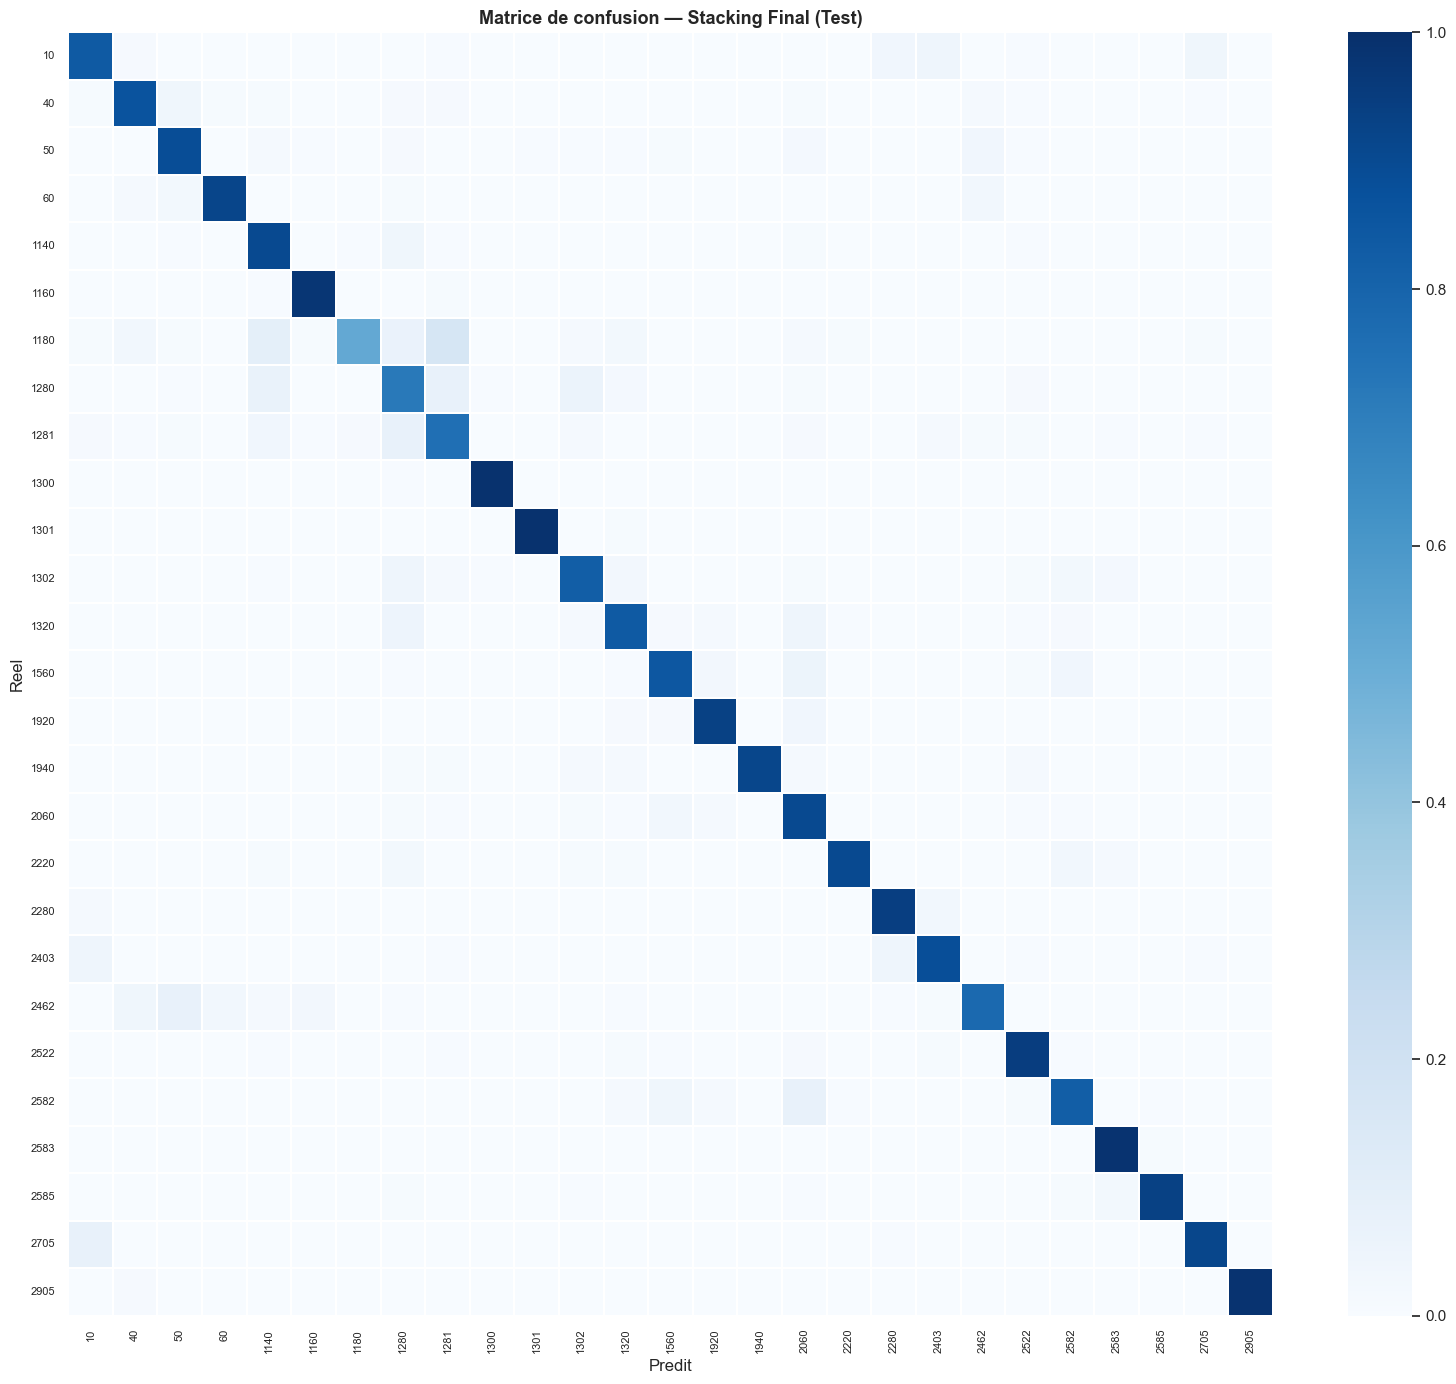

In [69]:
with open(CFG['models_dir'] / 'label_encoder.pkl', 'rb') as f:
    le = pickle.load(f)

y_pred_final = P_final_test.argmax(axis=1)
cm = confusion_matrix(y_test, y_pred_final)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm_norm, cmap='Blues', ax=ax, linewidths=0.2,
            xticklabels=le.classes_, yticklabels=le.classes_,
            vmin=0, vmax=1)
ax.set_xlabel('Predit', fontsize=12)
ax.set_ylabel('Reel', fontsize=12)
ax.set_title('Matrice de confusion — Stacking Final (Test)', fontsize=13, fontweight='bold')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
save_fig('stacking_confusion_matrix.png')
plt.show()

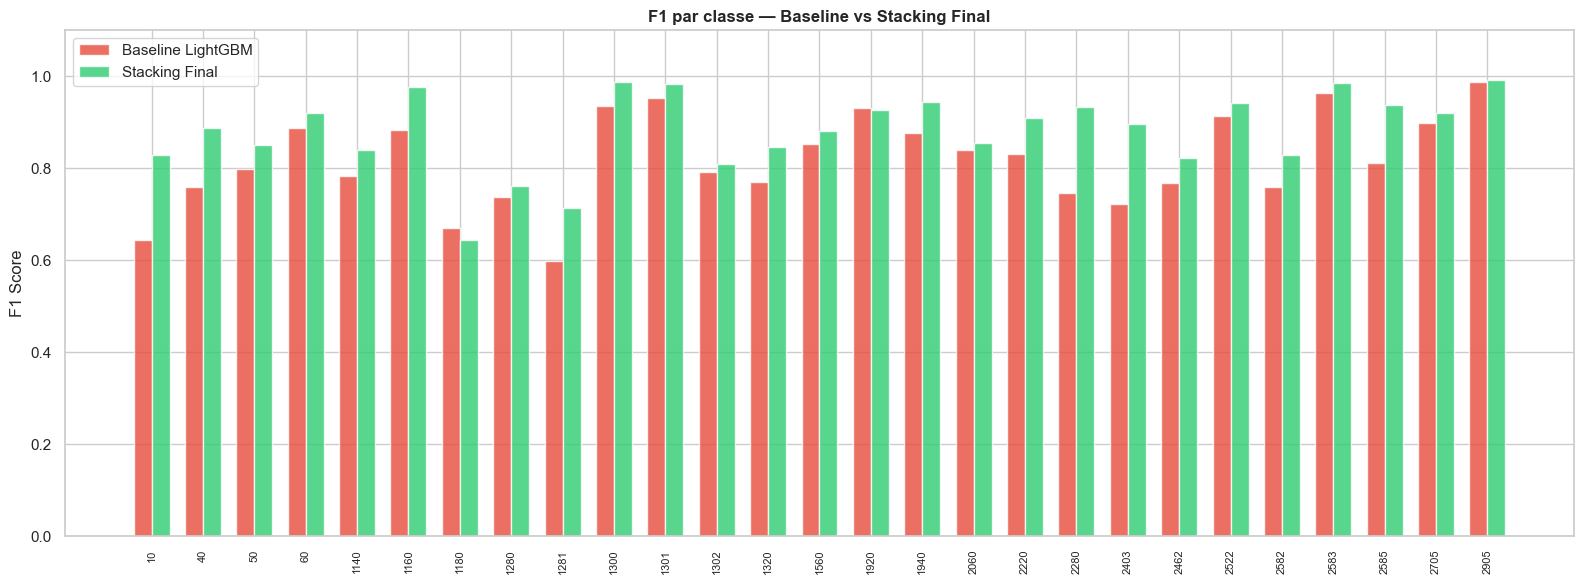

In [70]:
# F1 par classe : comparaison Baseline vs Stacking
f1_baseline = None
if (CFG['processed'] / 'P_baseline_test.npy').exists():
    P_bl = np.load(CFG['processed'] / 'P_baseline_test.npy')
    f1_baseline = f1_score(y_test, P_bl.argmax(1), average=None)

f1_stacking = f1_score(y_test, y_pred_final, average=None)

fig, ax = plt.subplots(figsize=(16, 6))
x = np.arange(CFG['n_classes'])
w = 0.35
if f1_baseline is not None:
    ax.bar(x - w/2, f1_baseline, w, label='Baseline LightGBM', alpha=0.8, color='#e74c3c')
ax.bar(x + w/2 if f1_baseline is not None else x,
        f1_stacking, w, label='Stacking Final', alpha=0.8, color='#2ecc71')
ax.set_xticks(x)
ax.set_xticklabels(le.classes_, rotation=90, fontsize=8)
ax.set_ylim(0, 1.1)
ax.set_ylabel('F1 Score')
ax.set_title('F1 par classe — Baseline vs Stacking Final', fontweight='bold')
ax.legend()
plt.tight_layout()
save_fig('stacking_f1_per_class.png')
plt.show()

### 8.2 Interprétabilité du Stacking

Analyse de la contribution relative des meta-features au classifieur final.

Calcul PI pour E6 (dim=61)...
Calcul PI pour E7 (dim=71)...


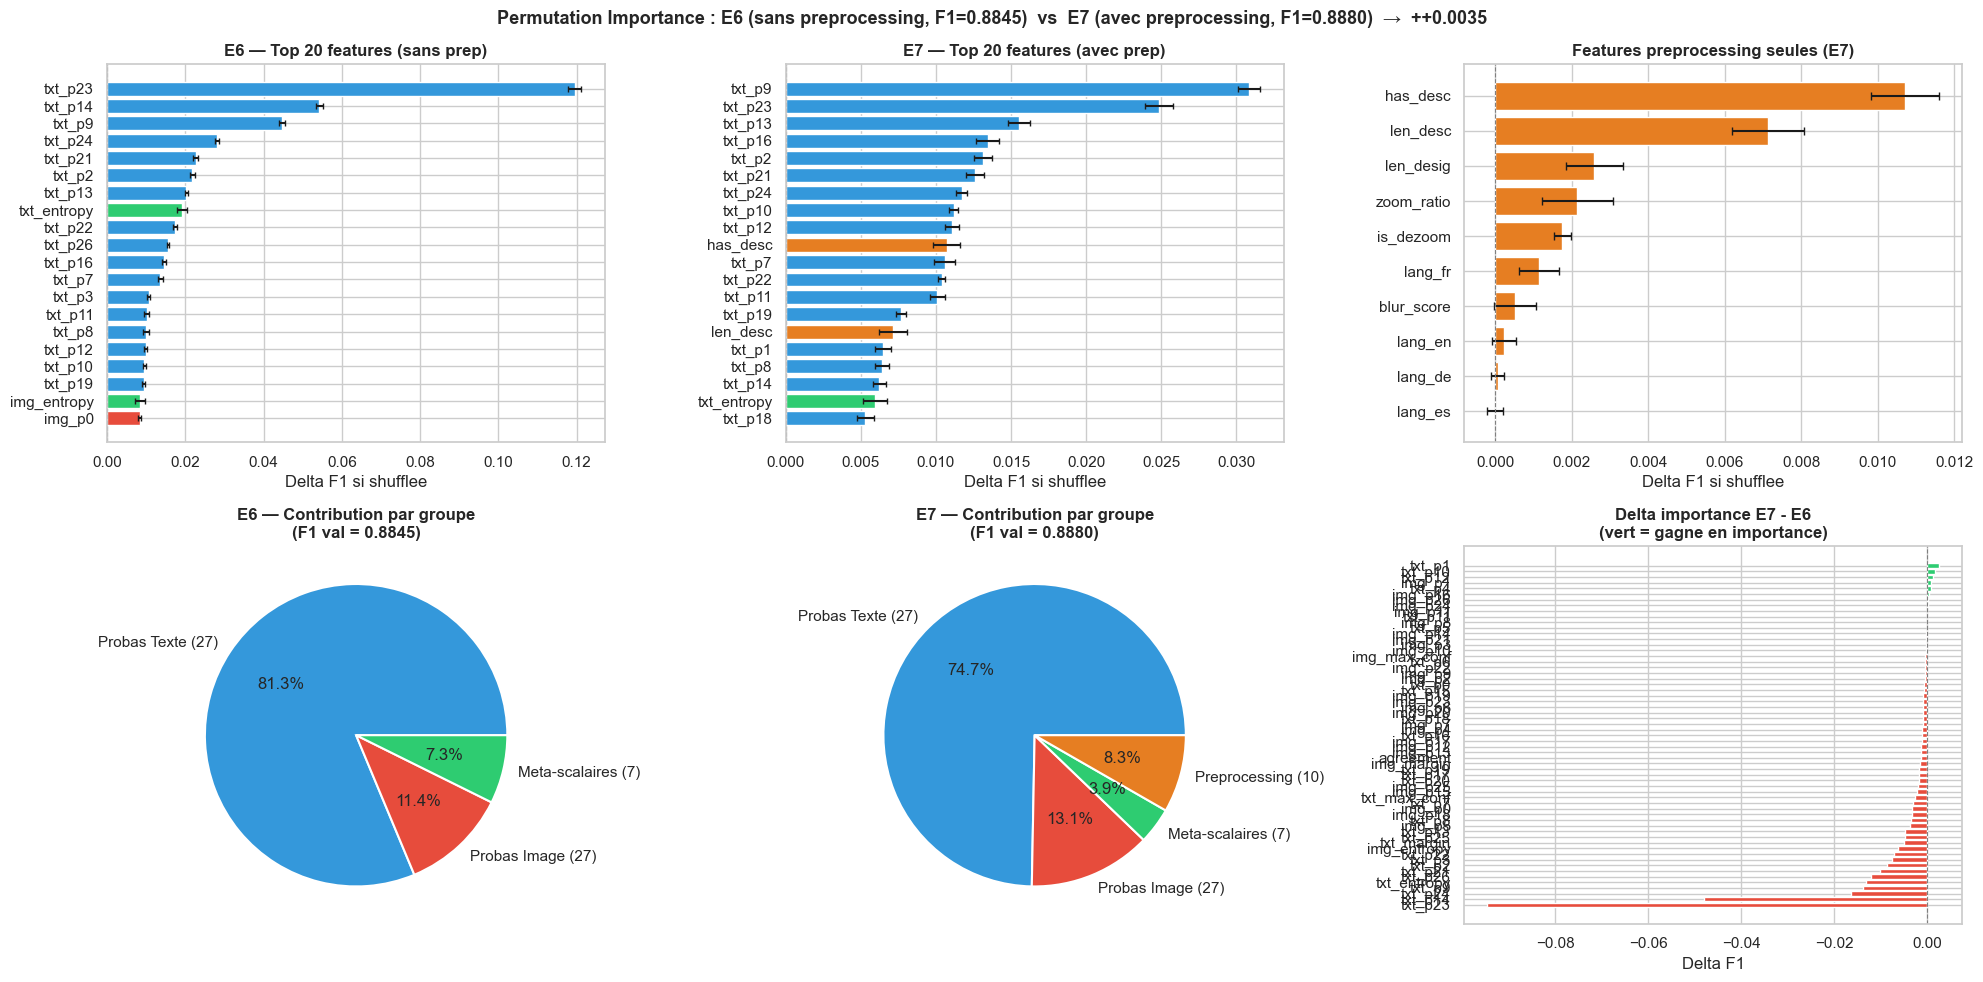


Importance cumulee des 10 features preprocessing dans E7 : 0.0263
Gain F1 val E6 -> E7 : +0.0035

Top features preprocessing :
   feature  importance      std
  has_desc    0.010717 0.000897
  len_desc    0.007140 0.000945
 len_desig    0.002586 0.000743
zoom_ratio    0.002145 0.000923
 is_dezoom    0.001757 0.000224
   lang_fr    0.001150 0.000522
blur_score    0.000521 0.000550
   lang_en    0.000227 0.000309
   lang_de    0.000070 0.000170
   lang_es   -0.000006 0.000213


In [71]:
# ── Noms de features ──────────────────────────────────────────────────────────
n_cl = CFG['n_classes']

PREP_NAMES = ['lang_fr', 'lang_en', 'lang_es', 'lang_de',
              'has_desc', 'len_desig', 'len_desc',
              'zoom_ratio', 'blur_score', 'is_dezoom']

BASE_NAMES = (
    [f'txt_p{i}' for i in range(n_cl)] +
    [f'img_p{i}' for i in range(n_cl)] +
    ['txt_entropy', 'txt_margin', 'txt_max_conf',
     'img_entropy', 'img_margin', 'img_max_conf', 'agreement']
)  # 61

def feat_names_for(n_feat):
    if n_feat == len(BASE_NAMES):
        return BASE_NAMES
    elif n_feat == len(BASE_NAMES) + len(PREP_NAMES):
        return BASE_NAMES + PREP_NAMES
    return [f'feat_{i}' for i in range(n_feat)]

# ── Permutation Importance helper ─────────────────────────────────────────────
from sklearn.inspection import permutation_importance

def compute_pi(clf, X_vl, y_vl, n_repeats=10):
    # n_jobs=1 pour les modeles PyTorch (non serialisables entre workers joblib)
    _jobs = 1 if isinstance(clf, MetaMLPClassifier) else -1
    pi = permutation_importance(
        clf, X_vl, y_vl,
        scoring='f1_weighted', n_repeats=n_repeats,
        random_state=42, n_jobs=_jobs,
    )
    names = feat_names_for(X_vl.shape[1])
    return pd.DataFrame({
        'feature':    names,
        'importance': pi.importances_mean,
        'std':        pi.importances_std,
    }).sort_values('importance', ascending=False).reset_index(drop=True)

# ── Trouver E6 (sans prep) et E7 (avec prep) dans experiments ─────────────────
exp_map = {e[0]: e for e in experiments}  # name -> (name, X_tr, X_vl, X_te, clf)
res_map = {r['name']: r for r in results}

e6_row = exp_map.get('E6_meta_mlp')
e7_row = exp_map.get('E7_meta_prep_mlp')

if e6_row is None or e7_row is None:
    print('E6 ou E7 non trouve dans experiments.')
else:
    _, _, X_vl_e6, _, _ = e6_row
    _, _, X_vl_e7, _, _ = e7_row
    clf_e6 = res_map['E6_meta_mlp']['clf']
    clf_e7 = res_map['E7_meta_prep_mlp']['clf']
    f1_e6  = res_map['E6_meta_mlp']['F1_Val']
    f1_e7  = res_map['E7_meta_prep_mlp']['F1_Val']

    print(f'Calcul PI pour E6 (dim={X_vl_e6.shape[1]})...')
    pi_e6 = compute_pi(clf_e6, X_vl_e6, y_val)
    print(f'Calcul PI pour E7 (dim={X_vl_e7.shape[1]})...')
    pi_e7 = compute_pi(clf_e7, X_vl_e7, y_val)

    # ── Groupes d importance ──────────────────────────────────────────────────
    BASE_GROUPS = {
        'Probas Texte (27)':  [f'txt_p{i}' for i in range(n_cl)],
        'Probas Image (27)':  [f'img_p{i}' for i in range(n_cl)],
        'Meta-scalaires (7)': ['txt_entropy', 'txt_margin', 'txt_max_conf',
                               'img_entropy', 'img_margin', 'img_max_conf', 'agreement'],
    }

    def group_sum(df, feat_list):
        return max(df.loc[df['feature'].isin(feat_list), 'importance'].sum(), 0)

    colors_base = ['#3498db', '#e74c3c', '#2ecc71']
    color_prep  = '#e67e22'

    # ── Figure ────────────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(20, 10))
    fig.suptitle(
        f'Permutation Importance : E6 (sans preprocessing, F1={f1_e6:.4f})'
        f'  vs  E7 (avec preprocessing, F1={f1_e7:.4f})'
        f'  →  +{f1_e7 - f1_e6:+.4f}',
        fontsize=13, fontweight='bold',
    )

    # -- Col 1 : E6 top 20 --------------------------------------------------------
    ax1 = fig.add_subplot(2, 3, 1)
    top_e6 = pi_e6.head(20)
    colors_e6 = ['#3498db' if f.startswith('txt_p') else
                 '#e74c3c' if f.startswith('img_p') else '#2ecc71'
                 for f in top_e6['feature']]
    ax1.barh(top_e6['feature'][::-1], top_e6['importance'][::-1],
             xerr=top_e6['std'][::-1], color=colors_e6[::-1], capsize=2)
    ax1.set_title('E6 — Top 20 features (sans prep)', fontweight='bold')
    ax1.set_xlabel('Delta F1 si shufflee')
    ax1.axvline(0, color='grey', linestyle='--', linewidth=0.8)

    # -- Col 2 : E7 top 20 --------------------------------------------------------
    ax2 = fig.add_subplot(2, 3, 2)
    top_e7 = pi_e7.head(20)
    colors_e7 = [color_prep if f in PREP_NAMES else
                 '#3498db' if f.startswith('txt_p') else
                 '#e74c3c' if f.startswith('img_p') else '#2ecc71'
                 for f in top_e7['feature']]
    ax2.barh(top_e7['feature'][::-1], top_e7['importance'][::-1],
             xerr=top_e7['std'][::-1], color=colors_e7[::-1], capsize=2)
    ax2.set_title('E7 — Top 20 features (avec prep)', fontweight='bold')
    ax2.set_xlabel('Delta F1 si shufflee')
    ax2.axvline(0, color='grey', linestyle='--', linewidth=0.8)

    # -- Col 3 : Focus features preprocessing dans E7 ─────────────────────────
    ax3 = fig.add_subplot(2, 3, 3)
    prep_imp = (pi_e7[pi_e7['feature'].isin(PREP_NAMES)]
                .sort_values('importance', ascending=False))
    ax3.barh(prep_imp['feature'][::-1], prep_imp['importance'][::-1],
             xerr=prep_imp['std'][::-1], color=color_prep, capsize=3)
    ax3.set_title('Features preprocessing seules (E7)', fontweight='bold')
    ax3.set_xlabel('Delta F1 si shufflee')
    ax3.axvline(0, color='grey', linestyle='--', linewidth=0.8)

    # -- Row 2 : Pies comparatifs ─────────────────────────────────────────────
    ax4 = fig.add_subplot(2, 3, 4)
    g6 = {k: group_sum(pi_e6, v) for k, v in BASE_GROUPS.items()}
    g6 = {k: v for k, v in g6.items() if v > 0}
    ax4.pie(g6.values(), labels=g6.keys(), autopct='%1.1f%%',
            colors=colors_base[:len(g6)],
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
    ax4.set_title(f'E6 — Contribution par groupe\n(F1 val = {f1_e6:.4f})', fontweight='bold')

    ax5 = fig.add_subplot(2, 3, 5)
    g7 = {k: group_sum(pi_e7, v) for k, v in BASE_GROUPS.items()}
    g7['Preprocessing (10)'] = group_sum(pi_e7, PREP_NAMES)
    g7 = {k: v for k, v in g7.items() if v > 0}
    colors_pie7 = colors_base + [color_prep]
    ax5.pie(g7.values(), labels=g7.keys(), autopct='%1.1f%%',
            colors=colors_pie7[:len(g7)],
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
    ax5.set_title(f'E7 — Contribution par groupe\n(F1 val = {f1_e7:.4f})', fontweight='bold')

    # -- Row 2 col 3 : Delta importance E7 - E6 par feature commune ───────────
    ax6 = fig.add_subplot(2, 3, 6)
    common = set(pi_e6['feature']) & set(pi_e7['feature'])
    delta_df = (pi_e7[pi_e7['feature'].isin(common)]
                .set_index('feature')[['importance']]
                .join(pi_e6[pi_e6['feature'].isin(common)]
                      .set_index('feature')[['importance']], rsuffix='_e6')
                .assign(delta=lambda d: d['importance'] - d['importance_e6'])
                .sort_values('delta', ascending=False))
    bar_colors = [('#2ecc71' if v >= 0 else '#e74c3c') for v in delta_df['delta']]
    ax6.barh(delta_df.index[::-1], delta_df['delta'][::-1], color=bar_colors[::-1])
    ax6.set_title('Delta importance E7 - E6\n(vert = gagne en importance)', fontweight='bold')
    ax6.set_xlabel('Delta F1')
    ax6.axvline(0, color='grey', linestyle='--', linewidth=0.8)

    plt.tight_layout()
    save_fig('meta_features_distribution.png')
    plt.show()

    prep_total = group_sum(pi_e7, PREP_NAMES)
    print(f'\nImportance cumulee des 10 features preprocessing dans E7 : {prep_total:.4f}')
    print(f'Gain F1 val E6 -> E7 : {f1_e7 - f1_e6:+.4f}')
    print('\nTop features preprocessing :')
    print(prep_imp[['feature', 'importance', 'std']].to_string(index=False))


### 8.3 Analyse de la confiance des prédictions

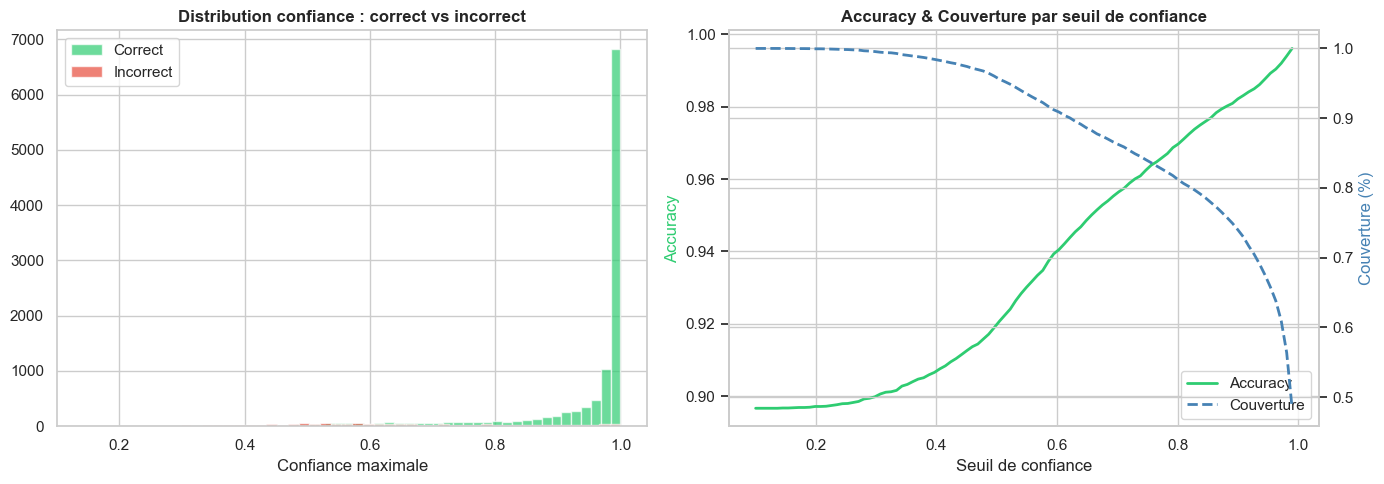

In [72]:
max_conf_final = P_final_test.max(axis=1)
correct = (y_pred_final == y_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution confiance : correct vs incorrect
axes[0].hist(max_conf_final[correct], bins=50, alpha=0.7, label='Correct', color='#2ecc71')
axes[0].hist(max_conf_final[~correct], bins=50, alpha=0.7, label='Incorrect', color='#e74c3c')
axes[0].set_xlabel('Confiance maximale')
axes[0].set_title('Distribution confiance : correct vs incorrect', fontweight='bold')
axes[0].legend()

# Accuracy par seuil de confiance
thresholds = np.linspace(0.1, 0.99, 100)
acc_at_conf = []
coverage_at_conf = []
for t in thresholds:
    mask = max_conf_final >= t
    if mask.sum() > 0:
        acc_at_conf.append(correct[mask].mean())
        coverage_at_conf.append(mask.mean())
    else:
        acc_at_conf.append(np.nan)
        coverage_at_conf.append(0)

ax2_twin = axes[1].twinx()
axes[1].plot(thresholds, acc_at_conf, color='#2ecc71', label='Accuracy', linewidth=2)
ax2_twin.plot(thresholds, coverage_at_conf, color='steelblue', linestyle='--', label='Couverture', linewidth=2)
axes[1].set_xlabel('Seuil de confiance')
axes[1].set_ylabel('Accuracy', color='#2ecc71')
ax2_twin.set_ylabel('Couverture (%)', color='steelblue')
axes[1].set_title('Accuracy & Couverture par seuil de confiance', fontweight='bold')

lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
axes[1].legend(lines1 + lines2, labels1 + labels2, loc='lower right')

plt.tight_layout()
save_fig('stacking_confidence_analysis.png')
plt.show()

---
## 9. Conclusion et Pistes d'Amélioration

In [73]:
print('=' * 70)
print('  NOTEBOOK 5 — BILAN STACKING FINAL & CONCLUSION')
print('=' * 70)
print()
print('BENCHMARK FINAL :')
print(bench_df.to_string(index=False))
print()
print(f'COMPARAISON SIGIR 2020 :')
print(f'  Notre meilleur score        : {best_result["F1_Test"]:.4f}')
print(f'  SIGIR 1er place (champion)  : {CFG["sigir_1st"]:.4f}')
print()

gap_champion = best_result['F1_Test'] - CFG['sigir_1st']
print(f'  vs champion  : {gap_champion:.4f}')

print()
print('PISTES D AMELIORATION :')
print('  1. Fine-tuning OOF de DINOv2 sur tous les folds (evite le leakage du FT in-sample)')
print('  2. Ajouter CamemBERT fine-tune OOF dans le stacking (modalite texte renforcee)')
print('  3. Augmentation des donnees texte (back-translation FR <-> EN)')
print('  4. Test-Time Augmentation (TTA) sur les images (flip, crop multiple, rotation)')
print('  5. Utiliser les soft-labels OOF comme cibles pour le fine-tuning (knowledge distillation)')
print('  6. Ensembler plusieurs checkpoints par modalite plutot que le meilleur unique')
print()

  NOTEBOOK 5 — BILAN STACKING FINAL & CONCLUSION

BENCHMARK FINAL :
          Experiment  F1_Val  F1_Test
    E7_meta_prep_mlp  0.8880   0.8879
    E8_crop_prep_mlp  0.8850   0.8849
         E6_meta_mlp  0.8845   0.8845
E3_text_image_logreg  0.8815   0.8825
      E4_meta_logreg  0.8828   0.8823
        E5_meta_lgbm  0.8756   0.8785
        E1_text_only  0.8646   0.8642
     E0_baseline_nb2  0.8262   0.8321
       E2_image_only  0.7534   0.7462

COMPARAISON SIGIR 2020 :
  Notre meilleur score        : 0.8963
  SIGIR 1er place (champion)  : 0.9194

  vs champion  : -0.0231

PISTES D AMELIORATION :
  1. Fine-tuning OOF de DINOv2 sur tous les folds (evite le leakage du FT in-sample)
  2. Ajouter CamemBERT fine-tune OOF dans le stacking (modalite texte renforcee)
  3. Augmentation des donnees texte (back-translation FR <-> EN)
  4. Test-Time Augmentation (TTA) sur les images (flip, crop multiple, rotation)
  5. Utiliser les soft-labels OOF comme cibles pour le fine-tuning (knowledge distill

---
## 10. Export des résultats pour l'application Streamlit

In [74]:
# Tableau de synthese pour l'app Streamlit (onglet benchmark)
sigir_df = pd.DataFrame([
    {'Systeme': 'SIGIR 2020 — 1er place',   'F1_Test': CFG['sigir_1st'],      'Type': 'Reference'},
])

our_df = pd.DataFrame(all_results, columns=['Systeme', 'F1_Test'])
our_df['Type'] = 'Nos modeles'

full_bench = pd.concat([our_df, sigir_df], ignore_index=True).sort_values('F1_Test', ascending=False)
full_bench.to_csv(CFG['models_dir'] / 'benchmark_final.csv', index=False)

print('Benchmark final sauvegarde : models/clean/benchmark_final.csv')
print(full_bench.to_string(index=False))

print('\nFICHIERS CLES POUR STREAMLIT :')
streamlit_files = [
    CFG['models_dir'] / 'meta_best.pkl',
    CFG['models_dir'] / 'label_encoder.pkl',
    CFG['models_dir'] / 'tfidf_vectorizer.pkl',
    CFG['models_dir'] / 'benchmark_final.csv',
    CFG['models_dir'] / 'ctfidf_centroids.npy',
    CFG['processed']  / 'stats_par_classe.csv',
]
for p in streamlit_files:
    print(f'  [{"OK" if p.exists() else "MANQUANT"}] {p.name}')

Benchmark final sauvegarde : models/clean/benchmark_final.csv
                Systeme  F1_Test        Type
 SIGIR 2020 — 1er place 0.919400   Reference
   Stacking final (NB5) 0.896300 Nos modeles
       Texte seul (NB3) 0.863249 Nos modeles
Baseline LightGBM (NB2) 0.832066 Nos modeles
      Image seule (NB4) 0.748623 Nos modeles

FICHIERS CLES POUR STREAMLIT :
  [OK] meta_best.pkl
  [OK] label_encoder.pkl
  [OK] tfidf_vectorizer.pkl
  [OK] benchmark_final.csv
  [OK] ctfidf_centroids.npy
  [OK] stats_par_classe.csv
